In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mode
from sklearn.base import clone
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import ShuffleSplit
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore', message='invalid value encountered in cast', category=RuntimeWarning)

ModuleNotFoundError: No module named 'scipy'

# 1. Data
#### In this assignment, you are expected to build a random forest that classifies a toy dataset.

#### a. Read the data from the file (data.csv). It contains 10000 samples and two features for each sample. Split the data into train and test sets with 0.2 test size.

In [ ]:
# read data
data = pd.read_csv('data.csv', index_col=0)

X = data[['X1', 'X2']]
y = data['y'].astype(int)

print(data.shape)
data.head()

(10000, 3)


,X1,X2,y
0,0.940291,0.122306,1.0
1,0.124540,-0.424775,0.0
2,0.261988,0.508414,0.0
3,-0.495238,0.072589,0.0
4,-0.879413,0.549373,0.0


#### b. Visualize the data using scatter plot.

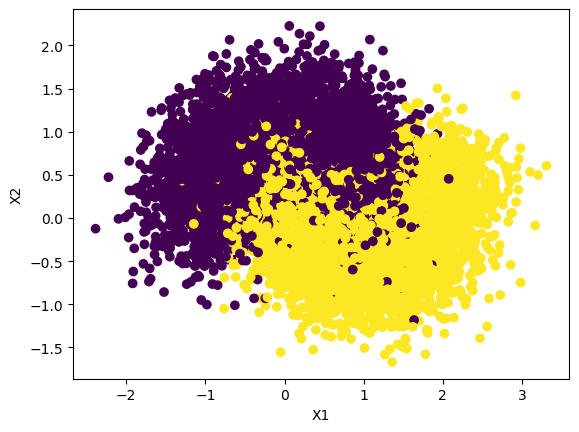

In [ ]:
# visualize the data using scatter plot
plt.scatter(X['X1'], X['X2'], c=y)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

#### c. Split the data into train and test sets with 20% test set size.

In [ ]:
# split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

# 2. Decision Tree

#### a. Train a DecisionTreeClassifier on the data. Use GridSearchCV to tune the hyperparameters.

In [ ]:
# create parameter value combinations
params = {
    'max_leaf_nodes': list(range(2, 100)),
    'max_depth': [1, 2, 3, 4, 5, 6],
    'min_samples_split': [2, 3, 4]
}

# find best hyperparameter values using grid search
grid_search_cv = GridSearchCV(DecisionTreeClassifier(random_state=42),
                              params,
                              cv=3)

grid_search_cv.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [1, 2, 3, 4, 5, 6],
                         'max_leaf_nodes': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                            13, 14, 15, 16, 17, 18, 19, 20, 21,
                                            22, 23, 24, 25, 26, 27, 28, 29, 30,
                                            31, ...],
                         'min_samples_split': [2, 3, 4]})

In [ ]:
# check the best model
grid_search_cv.best_estimator_

DecisionTreeClassifier(max_depth=6, max_leaf_nodes=17, random_state=42)

#### b. Train the best model on the whole train set (do you need to?) and evaluate the model on the test set.

In [ ]:
# get predictions using the best model and evaluate
y_pred = grid_search_cv.best_estimator_.predict(X_test)
accuracy_score(y_test, y_pred)

0.8595

# 3. Random Forest

#### a. Generate 1000 subsets of the training set, each containing 100 randomly chosen instances. You can use ShuffleSplit.

In [ ]:
# convert data to numpy arrays for convenience
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

In [ ]:
# create 1000 subsets of 100 random instances
n_trees = 1000
n_instances = 100

mini_sets = []

rs = ShuffleSplit(n_splits=n_trees,
                  train_size=n_instances,
                  random_state=42)

for mini_train_index, mini_test_index in rs.split(X_train):
    X_mini_train = X_train[mini_train_index]
    y_mini_train = y_train[mini_train_index]
    mini_sets.append((X_mini_train, y_mini_train))

#### b. Train one tree on each subset, using the best model you previously found. Evaluate the performance of the trees using the test set. Did you get lower or higher accuracy? Why?

In [ ]:
# create a forest of decision trees using the best model from grid search cross-validation
forest = [clone(grid_search_cv.best_estimator_) for _ in range(n_trees)]

accuracy_scores = []

# train the individual trees and evaluate
for tree, (X_mini_train, y_mini_train) in zip(forest, mini_sets):
    tree.fit(X_mini_train, y_mini_train)

    y_pred = tree.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred))

np.mean(accuracy_scores)

0.805671

#### c. For each instance in the test set, predict its class using 1000 trees, and keep only the most frequent prediction. You can use _mode_ from scipy.stats. Evaluate these predictions. Did you get lower or higher accuracy than the model in 2?

In [ ]:
# make predictions
Y_pred = np.empty([n_trees, len(X_test)], dtype=np.uint8)

for tree_index, tree in enumerate(forest):
    Y_pred[tree_index] = tree.predict(X_test)

In [ ]:
# identify the most frequent prediction for each test case
y_pred_majority_votes, n_votes = mode(Y_pred, axis=0, keepdims=False)

In [ ]:
# evaluate the forest
accuracy_score(y_test, y_pred_majority_votes)

0.873